In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("cancer prediction data.csv")
print(df.shape)
df.head()


(569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [2]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print(df["diagnosis"].value_counts())

Missing values: 0
Duplicate rows: 0
diagnosis
B    357
M    212
Name: count, dtype: int64


In [3]:
y = (df["diagnosis"] == "M").astype(int)   # 1 = malignant, 0 = benign
X = df.drop(columns=["id", "diagnosis"])   # id carries no information
print(X.shape, y.mean())

(569, 30) 0.37258347978910367


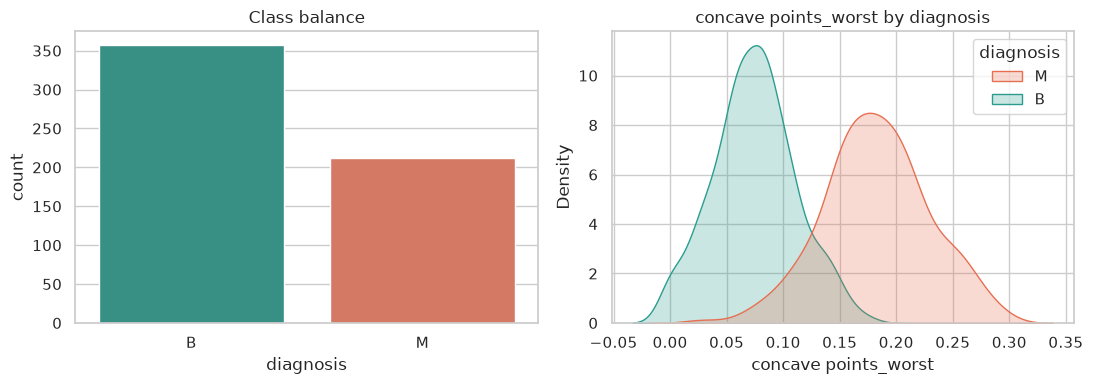

In [4]:
sns.set_theme(style="whitegrid")
palette = {"B": "#2a9d8f", "M": "#e76f51"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(data=df, x="diagnosis", order=["B", "M"], palette=palette, ax=axes[0])
axes[0].set_title("Class balance")

sns.kdeplot(data=df, x="concave points_worst", hue="diagnosis",
            palette=palette, fill=True, common_norm=False, ax=axes[1])
axes[1].set_title("concave points_worst by diagnosis")

plt.tight_layout()
plt.show()

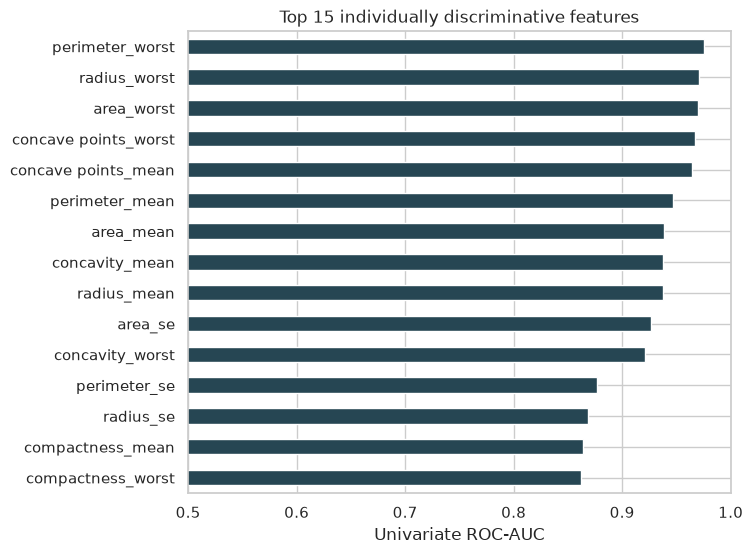

In [5]:
from sklearn.metrics import roc_auc_score

auc = {c: roc_auc_score(y, X[c]) for c in X.columns}
auc = pd.Series({c: max(a, 1 - a) for c, a in auc.items()}).sort_values(ascending=False)

auc.head(15)[::-1].plot.barh(figsize=(7, 6), color="#264653")
plt.xlim(0.5, 1.0)
plt.xlabel("Univariate ROC-AUC")
plt.title("Top 15 individually discriminative features")
plt.show()

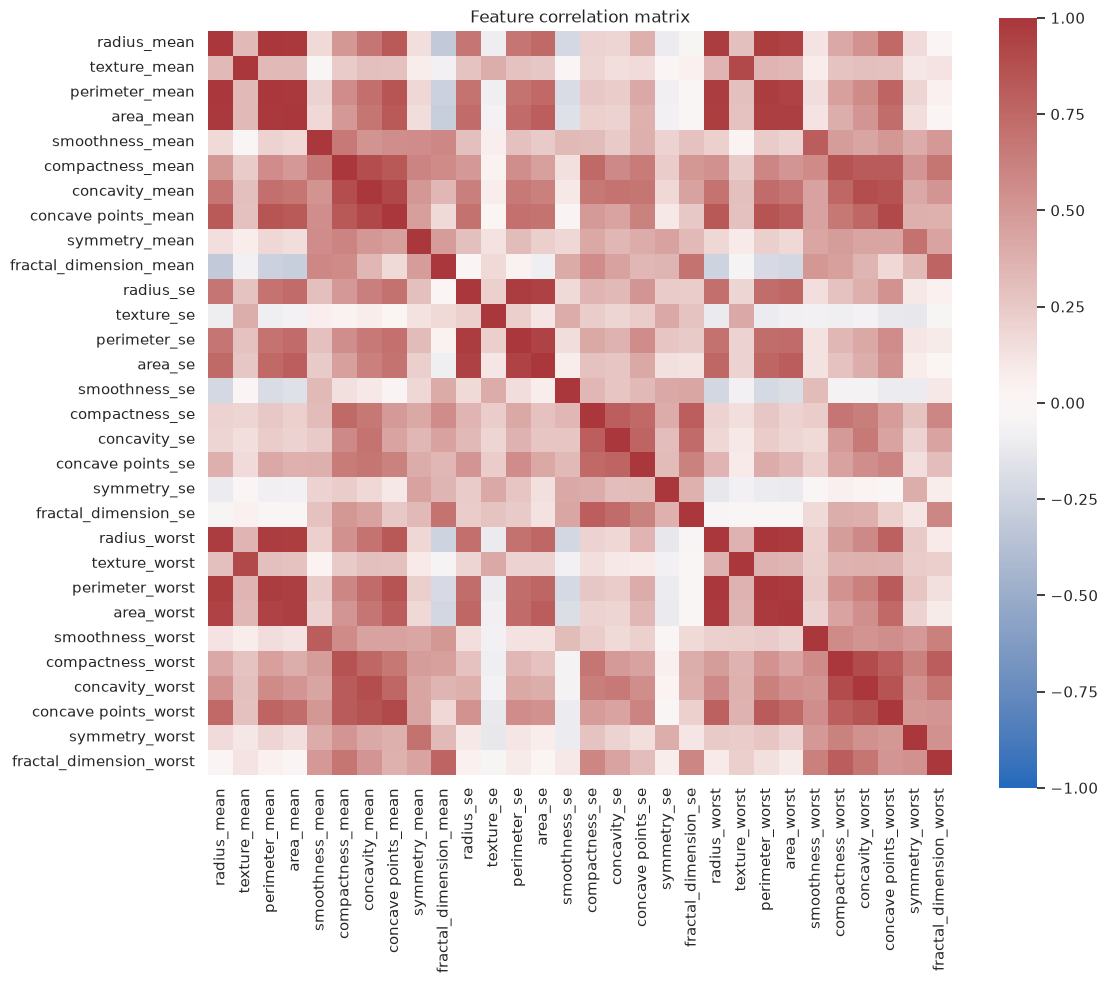

             level_0          level_1         r
2        radius_mean   perimeter_mean  0.997855
622     radius_worst  perimeter_worst  0.993708
3        radius_mean        area_mean  0.987357
63    perimeter_mean        area_mean  0.986507
623     radius_worst       area_worst  0.984015
683  perimeter_worst       area_worst  0.977578
312        radius_se     perimeter_se  0.972794
82    perimeter_mean  perimeter_worst  0.970387


In [6]:
corr = X.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, square=True)
plt.title("Feature correlation matrix")
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().rename("r").reset_index())
print(pairs[pairs["r"].abs() > 0.95].sort_values("r", ascending=False).head(8))

In [7]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape[0]} rows, {y_train.mean():.1%} malignant")
print(f"Test : {X_test.shape[0]} rows, {y_test.mean():.1%} malignant")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: 455 rows, 37.4% malignant
Test : 114 rows, 36.8% malignant


In [8]:
from sklearn.model_selection import cross_validate

pipe = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
])

scores = cross_validate(pipe, X_train, y_train, cv=cv,
                        scoring=["accuracy", "precision", "recall", "roc_auc"])

for m in ["accuracy", "precision", "recall", "roc_auc"]:
    print(f"{m:10s} {scores['test_' + m].mean():.4f}  (+/- {scores['test_' + m].std():.4f})")

accuracy   0.9736  (+/- 0.0149)
precision  0.9771  (+/- 0.0280)
recall     0.9529  (+/- 0.0399)
roc_auc    0.9958  (+/- 0.0047)


In [9]:
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

def make(model):
    return Pipeline([("scale", StandardScaler()), ("clf", model)])

models = {
    "Logistic Regression": make(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    "SVM (RBF)":           make(SVC(probability=True, random_state=RANDOM_STATE)),
    "KNN":                 make(KNeighborsClassifier()),
    "Decision Tree":       make(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    "Random Forest":       make(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
    "Gradient Boosting":   make(GradientBoostingClassifier(random_state=RANDOM_STATE)),
}

scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
rows = []
for name, pipe in models.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"model": name, **{m: s[f"test_{m}"].mean() for m in scoring}})

cv_results = pd.DataFrame(rows).set_index("model").sort_values("roc_auc", ascending=False)
cv_results.round(4)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.9736,0.9771,0.9529,0.9640,0.9958
SVM (RBF),0.9714,0.9769,0.9471,0.9610,0.9949
Gradient Boosting,0.9670,0.9646,0.9471,0.9553,0.9908
Random Forest,0.9604,0.9584,0.9353,0.9461,0.9880
KNN,0.9648,0.9875,0.9176,0.9510,0.9871
Decision Tree,0.9231,0.8996,0.8941,0.8962,0.9172


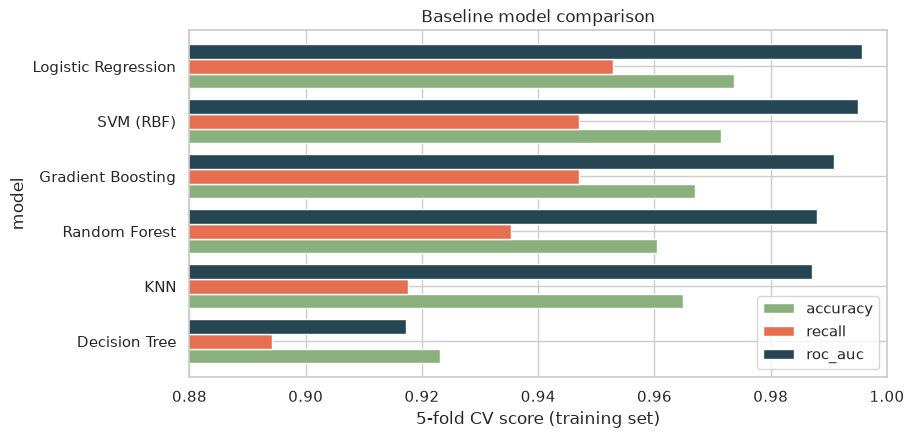

In [10]:
cv_results[["accuracy", "recall", "roc_auc"]].iloc[::-1].plot.barh(
    figsize=(9, 4.5), width=0.8, color=["#8ab17d", "#e76f51", "#264653"])
plt.xlim(0.88, 1.0)
plt.xlabel("5-fold CV score (training set)")
plt.title("Baseline model comparison")
plt.show()

In [11]:
from sklearn.model_selection import GridSearchCV

grids = {
    "Logistic Regression": (
        make(LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
        {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30]}),
    "SVM (RBF)": (
        make(SVC(probability=True, random_state=RANDOM_STATE)),
        {"clf__C": [0.3, 1, 3, 10, 30],
         "clf__gamma": ["scale", 0.003, 0.01, 0.03, 0.1]}),
    "Random Forest": (
        make(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)),
        {"clf__max_depth": [None, 6, 12],
         "clf__min_samples_leaf": [1, 2, 4],
         "clf__max_features": ["sqrt", 0.3]}),
}

tuned = {}
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned[name] = gs
    print(f"{name:20s} CV ROC-AUC = {gs.best_score_:.4f}   best = {gs.best_params_}")

best_name = max(tuned, key=lambda k: tuned[k].best_score_)
best_model = tuned[best_name].best_estimator_
print("\nSelected model:", best_name)

Logistic Regression  CV ROC-AUC = 0.9958   best = {'clf__C': 1}
SVM (RBF)            CV ROC-AUC = 0.9961   best = {'clf__C': 30, 'clf__gamma': 0.003}
Random Forest        CV ROC-AUC = 0.9882   best = {'clf__max_depth': None, 'clf__max_features': 0.3, 'clf__min_samples_leaf': 1}

Selected model: SVM (RBF)


In [12]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay)

proba = best_model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print(f"Model: {best_name} (threshold 0.5)\n")
print(classification_report(y_test, pred, target_names=["Benign", "Malignant"], digits=3))
print("ROC-AUC:", round(roc_auc_score(y_test, proba), 4))

tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

Model: SVM (RBF) (threshold 0.5)

              precision    recall  f1-score   support

      Benign      0.973     1.000     0.986        72
   Malignant      1.000     0.952     0.976        42

    accuracy                          0.982       114
   macro avg      0.986     0.976     0.981       114
weighted avg      0.983     0.982     0.982       114

ROC-AUC: 0.996
TN=72  FP=0  FN=2  TP=40


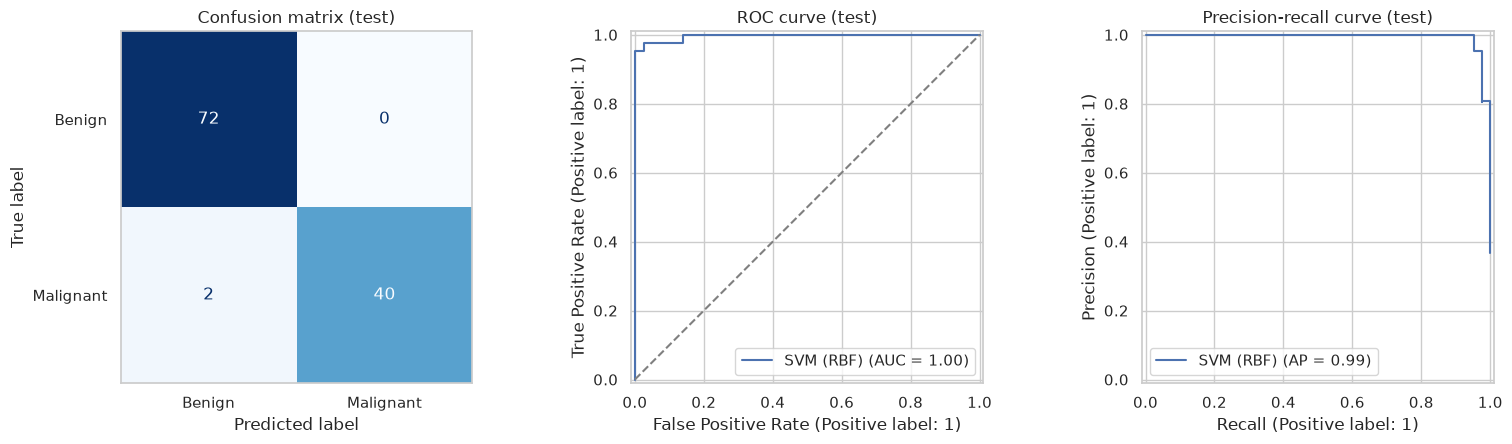

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["Benign", "Malignant"],
    cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Confusion matrix (test)")
axes[0].grid(False)

RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1], name=best_name)
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_title("ROC curve (test)")

PrecisionRecallDisplay.from_predictions(y_test, proba, ax=axes[2], name=best_name)
axes[2].set_title("Precision-recall curve (test)")

plt.tight_layout()
plt.show()

In [14]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import recall_score, precision_score, accuracy_score, f1_score

# Out-of-fold probabilities on the training set
oof = cross_val_predict(best_model, X_train, y_train, cv=cv,
                        method="predict_proba", n_jobs=-1)[:, 1]

thresholds = np.linspace(0.02, 0.98, 97)
sweep = pd.DataFrame({
    "threshold": thresholds,
    "recall":    [recall_score(y_train, oof >= t) for t in thresholds],
    "precision": [precision_score(y_train, oof >= t, zero_division=0) for t in thresholds],
})

TARGET_RECALL = 0.98
ok = sweep[sweep["recall"] >= TARGET_RECALL]
chosen = ok.sort_values(["precision", "threshold"], ascending=[False, False]).iloc[0]
THRESH = float(chosen["threshold"])
print(f"Chosen threshold = {THRESH:.2f} "
      f"(train recall {chosen['recall']:.3f}, precision {chosen['precision']:.3f})")

Chosen threshold = 0.25 (train recall 0.982, precision 0.923)


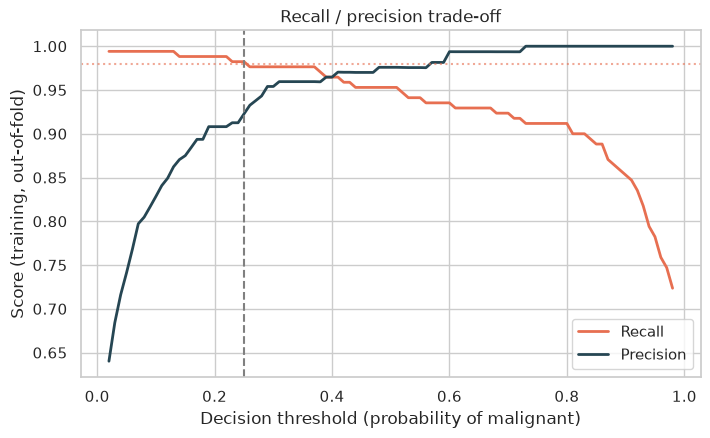

In [15]:
plt.figure(figsize=(8, 4.5))
plt.plot(sweep["threshold"], sweep["recall"], label="Recall", color="#e76f51", lw=2)
plt.plot(sweep["threshold"], sweep["precision"], label="Precision", color="#264653", lw=2)
plt.axvline(THRESH, ls="--", color="grey")
plt.axhline(TARGET_RECALL, ls=":", color="#e76f51", alpha=0.6)
plt.xlabel("Decision threshold (probability of malignant)")
plt.ylabel("Score (training, out-of-fold)")
plt.title("Recall / precision trade-off")
plt.legend()
plt.show()

In [16]:
pred_t = (proba >= THRESH).astype(int)

summary = pd.DataFrame({
    "Threshold 0.50": [accuracy_score(y_test, pred), precision_score(y_test, pred),
                       recall_score(y_test, pred), f1_score(y_test, pred)],
    f"Threshold {THRESH:.2f}": [accuracy_score(y_test, pred_t), precision_score(y_test, pred_t),
                                recall_score(y_test, pred_t), f1_score(y_test, pred_t)],
}, index=["accuracy", "precision", "recall", "f1"])
print(summary.round(3))

tn, fp, fn, tp = confusion_matrix(y_test, pred_t).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

           Threshold 0.50  Threshold 0.25
accuracy            0.982           0.965
precision           1.000           0.932
recall              0.952           0.976
f1                  0.976           0.953
TN=69  FP=3  FN=1  TP=41


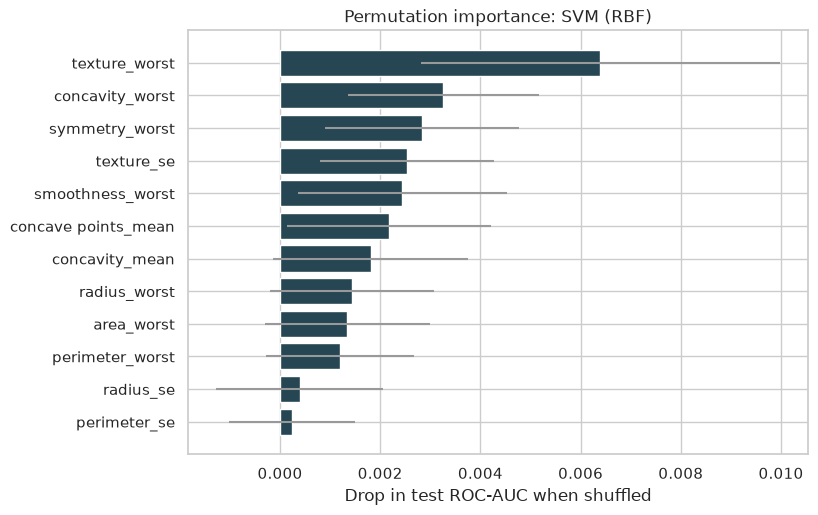

,feature,mean,std
21,texture_worst,0.0064,0.0036
26,concavity_worst,0.0033,0.0019
28,symmetry_worst,0.0028,0.0019
11,texture_se,0.0025,0.0017
24,smoothness_worst,0.0024,0.0021
7,concave points_mean,0.0022,0.0020


In [17]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)

imp = pd.DataFrame({"feature": X.columns,
                    "mean": perm.importances_mean,
                    "std": perm.importances_std}).sort_values("mean", ascending=False).head(12)

plt.figure(figsize=(8, 5.5))
plt.barh(imp["feature"][::-1], imp["mean"][::-1], xerr=imp["std"][::-1],
         color="#264653", ecolor="#999")
plt.xlabel("Drop in test ROC-AUC when shuffled")
plt.title(f"Permutation importance: {best_name}")
plt.show()
imp.head(6).round(4)

In [18]:
import joblib, os
os.makedirs("model", exist_ok=True)

joblib.dump({"pipeline": best_model, "threshold": THRESH, "features": list(X.columns)},
            "model/breast_cancer_model.joblib")

bundle = joblib.load("model/breast_cancer_model.joblib")

def predict_sample(row):
    p = bundle["pipeline"].predict_proba(row[bundle["features"]].to_frame().T)[0, 1]
    return ("Malignant" if p >= bundle["threshold"] else "Benign"), float(p)

for idx in [y_test[y_test == 1].index[0], y_test[y_test == 0].index[0]]:
    label, p = predict_sample(X_test.loc[idx])
    actual = "Malignant" if y_test.loc[idx] == 1 else "Benign"
    print(f"row {idx}: predicted {label:9s} (P(malignant)={p:.3f}) | actual {actual}")

row 250: predicted Malignant (P(malignant)=1.000) | actual Malignant
row 120: predicted Benign    (P(malignant)=0.001) | actual Benign


                              mean_drop     std
size (radius/perimeter/area)     0.1780  0.0329
texture                          0.0161  0.0075
concavity                        0.0157  0.0059
concave points                   0.0066  0.0028
smoothness                       0.0048  0.0025
symmetry                         0.0026  0.0020
compactness                      0.0010  0.0036
fractal dim.                     0.0007  0.0022


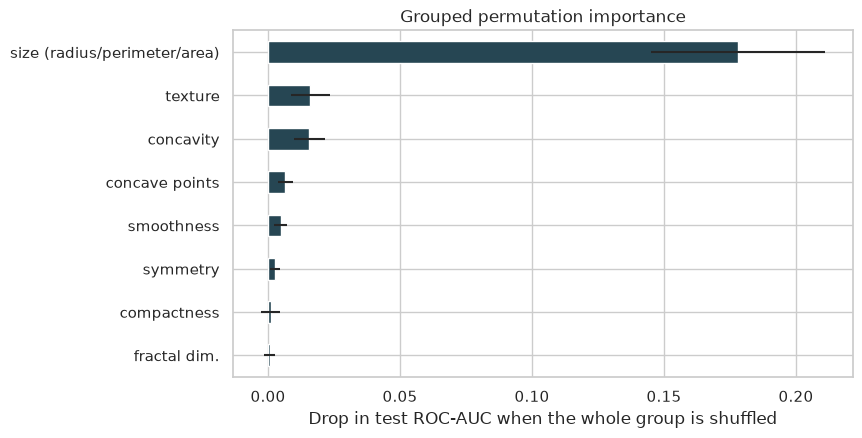

In [19]:
from sklearn.metrics import roc_auc_score

groups = {
    "size (radius/perimeter/area)": [c for c in X.columns if c.split("_")[0] in ("radius", "perimeter", "area")],
    "texture":        [c for c in X.columns if c.startswith("texture")],
    "smoothness":     [c for c in X.columns if c.startswith("smoothness")],
    "compactness":    [c for c in X.columns if c.startswith("compactness")],
    "concavity":      [c for c in X.columns if c.startswith("concavity")],
    "concave points": [c for c in X.columns if c.startswith("concave points")],
    "symmetry":       [c for c in X.columns if c.startswith("symmetry")],
    "fractal dim.":   [c for c in X.columns if c.startswith("fractal")],
}

base = roc_auc_score(y_test, best_model.predict_proba(X_test)[:, 1])
rng = np.random.RandomState(RANDOM_STATE)
res = {}
for g, cols in groups.items():
    drops = []
    for _ in range(30):
        Xp = X_test.copy()
        Xp[cols] = X_test[cols].values[rng.permutation(len(X_test))]   # shuffle the group together
        drops.append(base - roc_auc_score(y_test, best_model.predict_proba(Xp)[:, 1]))
    res[g] = (np.mean(drops), np.std(drops))

grp = pd.DataFrame(res, index=["mean_drop", "std"]).T.sort_values("mean_drop", ascending=False)
print(grp.round(4))

grp["mean_drop"][::-1].plot.barh(xerr=grp["std"][::-1], figsize=(8, 4.5), color="#264653")
plt.xlabel("Drop in test ROC-AUC when the whole group is shuffled")
plt.title("Grouped permutation importance")
plt.show()

In [20]:
!pip install gradio
